Part A

In [2]:
import numpy as np
from pathlib import Path
from PIL import Image

DATA_DIR = Path("data")  

images, labels = [], []
for subject_dir in sorted(DATA_DIR.glob("s*"), key=lambda p: int(p.name[1:])):
    subject_id = int(subject_dir.name[1:])
    files = sorted(
        [f for f in subject_dir.iterdir() if f.is_file()],
        key=lambda p: int(p.stem),
    )
    for img_path in files:
        img = Image.open(img_path).convert("L")   # force grayscale
        images.append(np.array(img, dtype=np.float64))
        labels.append(subject_id)

images = np.stack(images)
labels = np.array(labels)

print("Image array shape:", images.shape)          # expect (400, 112, 92)
print("Single image shape:", images[0].shape)
print("Intensity range:", images.min(), "to", images.max())
print("Subjects:", len(np.unique(labels)), "| images per subject:", np.bincount(labels)[1:].min())
print("Example file:", files[0].name)

Image array shape: (400, 112, 92)
Single image shape: (112, 92)
Intensity range: 0.0 to 251.0
Subjects: 40 | images per subject: 10
Example file: 1.pgm


In [3]:
# --- Flatten: each image (112, 92) -> vector of length 10304 ---
n_samples, h, w = images.shape
X = images.reshape(n_samples, h * w)      # (400, 10304)
y = labels                                # (400,)

print("Feature matrix X:", X.shape)
print("Labels y:", y.shape)

# --- Stratified split, done by hand (no sklearn needed for Part A/B/C) ---
rng = np.random.default_rng(seed=42)
N_TRAIN_PER_SUBJECT = 7

train_idx, test_idx = [], []
for subject in np.unique(y):
    idx = np.where(y == subject)[0]       # the 10 images of this subject
    idx = rng.permutation(idx)
    train_idx.extend(idx[:N_TRAIN_PER_SUBJECT])
    test_idx.extend(idx[N_TRAIN_PER_SUBJECT:])

train_idx = np.array(sorted(train_idx))
test_idx = np.array(sorted(test_idx))

X_train, y_train = X[train_idx], y[train_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Subjects in train:", len(np.unique(y_train)), "| in test:", len(np.unique(y_test)))
print("Train/test overlap:", len(set(train_idx) & set(test_idx)))   # should be 0

Feature matrix X: (400, 10304)
Labels y: (400,)
Train: (280, 10304) | Test: (120, 10304)
Subjects in train: 40 | in test: 40
Train/test overlap: 0


Part B

mean_face: (10304,)
Xc_train: (280, 10304) | Xc_test: (120, 10304)
Max |column mean| of Xc_train (should be ~0): 7.592656662122213e-14


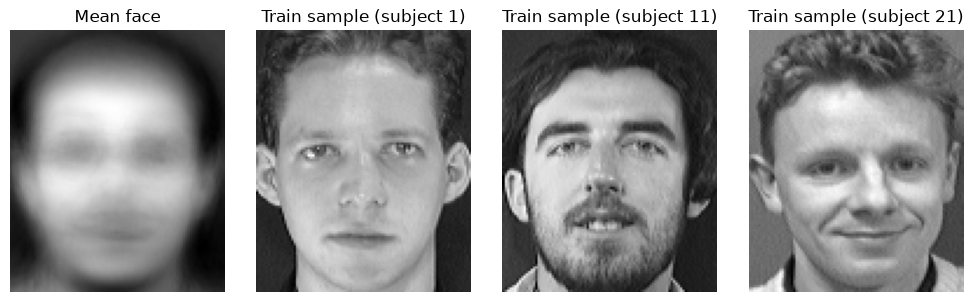

In [4]:
import matplotlib.pyplot as plt
mean_face = X_train.mean(axis=0)         

Xc_train = X_train - mean_face                
Xc_test  = X_test  - mean_face             

print("mean_face:", mean_face.shape)
print("Xc_train:", Xc_train.shape, "| Xc_test:", Xc_test.shape)
print("Max |column mean| of Xc_train (should be ~0):", np.abs(Xc_train.mean(axis=0)).max())

fig, axes = plt.subplots(1, 4, figsize=(10, 3))
axes[0].imshow(mean_face.reshape(h, w), cmap="gray")
axes[0].set_title("Mean face")
for i, ax in enumerate(axes[1:]):
    ax.imshow(X_train[i * 70].reshape(h, w), cmap="gray")
    ax.set_title(f"Train sample (subject {y_train[i * 70]})")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("mean_face.png", dpi=150)
plt.show()

In [5]:
n_train = Xc_train.shape[0]
U, S, Vt = np.linalg.svd(Xc_train, full_matrices=False)

print("U:", U.shape, "| S:", S.shape, "| Vt:", Vt.shape)
components_svd = Vt                              

eigvals_svd = (S ** 2) / (n_train - 1)     
explained_ratio = eigvals_svd / eigvals_svd.sum()

print("Top 5 singular values:", S[:5])
print("Top 5 explained variance ratios:", explained_ratio[:5])
print("Last singular value (should be ~0):", S[-1])
print("Orthonormal check (max |V Vt - I|):",
      np.abs(components_svd @ components_svd.T - np.eye(n_train)).max())

U: (280, 280) | S: (280,) | Vt: (280, 10304)
Top 5 singular values: [28179.09741894 23722.08867795 17784.59071535 15995.94436286
 15074.7864162 ]
Top 5 explained variance ratios: [0.17756948 0.12584038 0.07072972 0.05721817 0.05081787]
Last singular value (should be ~0): 1.3389358167208293e-11
Orthonormal check (max |V Vt - I|): 7.993605777301127e-15


In [6]:

G = Xc_train @ Xc_train.T / (n_train - 1)        
eigvals_eig, V_small = np.linalg.eigh(G)            
order = np.argsort(eigvals_eig)[::-1]
eigvals_eig = eigvals_eig[order]
V_small = V_small[:, order]
components_eig = Xc_train.T @ V_small               
components_eig /= np.linalg.norm(components_eig, axis=0, keepdims=True) + 1e-12
components_eig = components_eig.T                    
print("Max |eigval diff| (top 279):",
      np.abs(eigvals_eig[:279] - eigvals_svd[:279]).max())
dots = np.abs(np.sum(components_eig[:279] * components_svd[:279], axis=1))
print("Min |cos| between matching components (top 279):", dots.min())
print("Top 10 |cos|:", dots[:10])

Max |eigval diff| (top 279): 1.862645149230957e-09
Min |cos| between matching components (top 279): 0.999999999999996
Top 10 |cos|: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Components for >= 90% variance: 92
Variance actually retained at k90: 0.9003664373664891
k= 10 -> 0.603
k= 25 -> 0.737
k= 50 -> 0.829
k=100 -> 0.909
k=150 -> 0.951


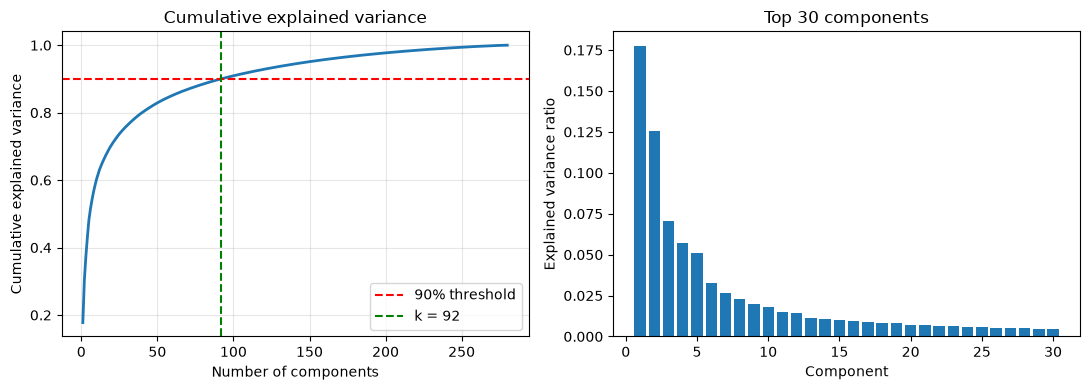

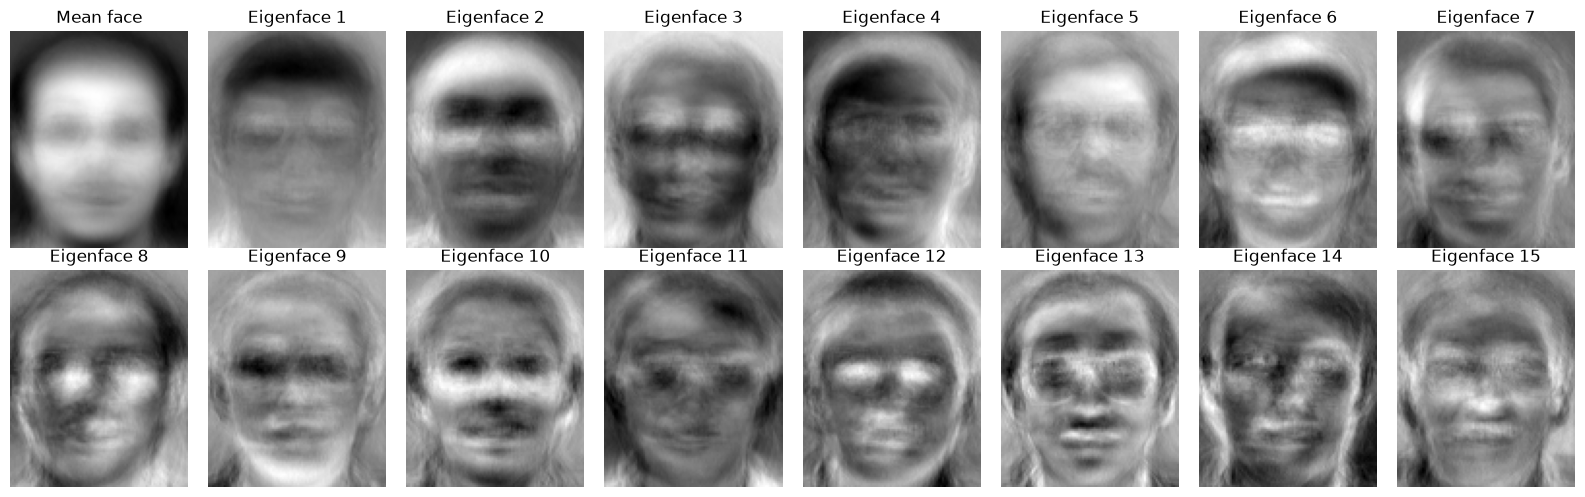

In [7]:
# --- Cumulative explained variance ---
cum_var = np.cumsum(explained_ratio)

# smallest k with cumulative variance >= 90%
k90 = int(np.searchsorted(cum_var, 0.90) + 1)
print("Components for >= 90% variance:", k90)
print("Variance actually retained at k90:", cum_var[k90 - 1])
for k in [10, 25, 50, 100, 150]:
    print(f"k={k:3d} -> {cum_var[k-1]:.3f}")

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.arange(1, len(cum_var) + 1), cum_var, lw=2)
axes[0].axhline(0.90, color="r", ls="--", label="90% threshold")
axes[0].axvline(k90, color="g", ls="--", label=f"k = {k90}")
axes[0].set_xlabel("Number of components")
axes[0].set_ylabel("Cumulative explained variance")
axes[0].set_title("Cumulative explained variance")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(np.arange(1, 31), explained_ratio[:30])
axes[1].set_xlabel("Component")
axes[1].set_ylabel("Explained variance ratio")
axes[1].set_title("Top 30 components")
plt.tight_layout()
plt.savefig("explained_variance.png", dpi=150)
plt.show()

# --- Eigenfaces: mean face + top 15 components ---
fig, axes = plt.subplots(2, 8, figsize=(16, 5))
axes[0, 0].imshow(mean_face.reshape(h, w), cmap="gray")
axes[0, 0].set_title("Mean face")
for i in range(15):
    ax = axes.flat[i + 1]
    ax.imshow(components_svd[i].reshape(h, w), cmap="gray")
    ax.set_title(f"Eigenface {i+1}")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig("eigenfaces.png", dpi=150)
plt.show()

Z_train: (280, 92) | Z_test: (120, 92)

Test reconstruction MSE:
k= 10  MSE=  658.69
k= 25  MSE=  488.67
k= 50  MSE=  396.20
k= 92  MSE=  335.52
k=150  MSE=  299.37


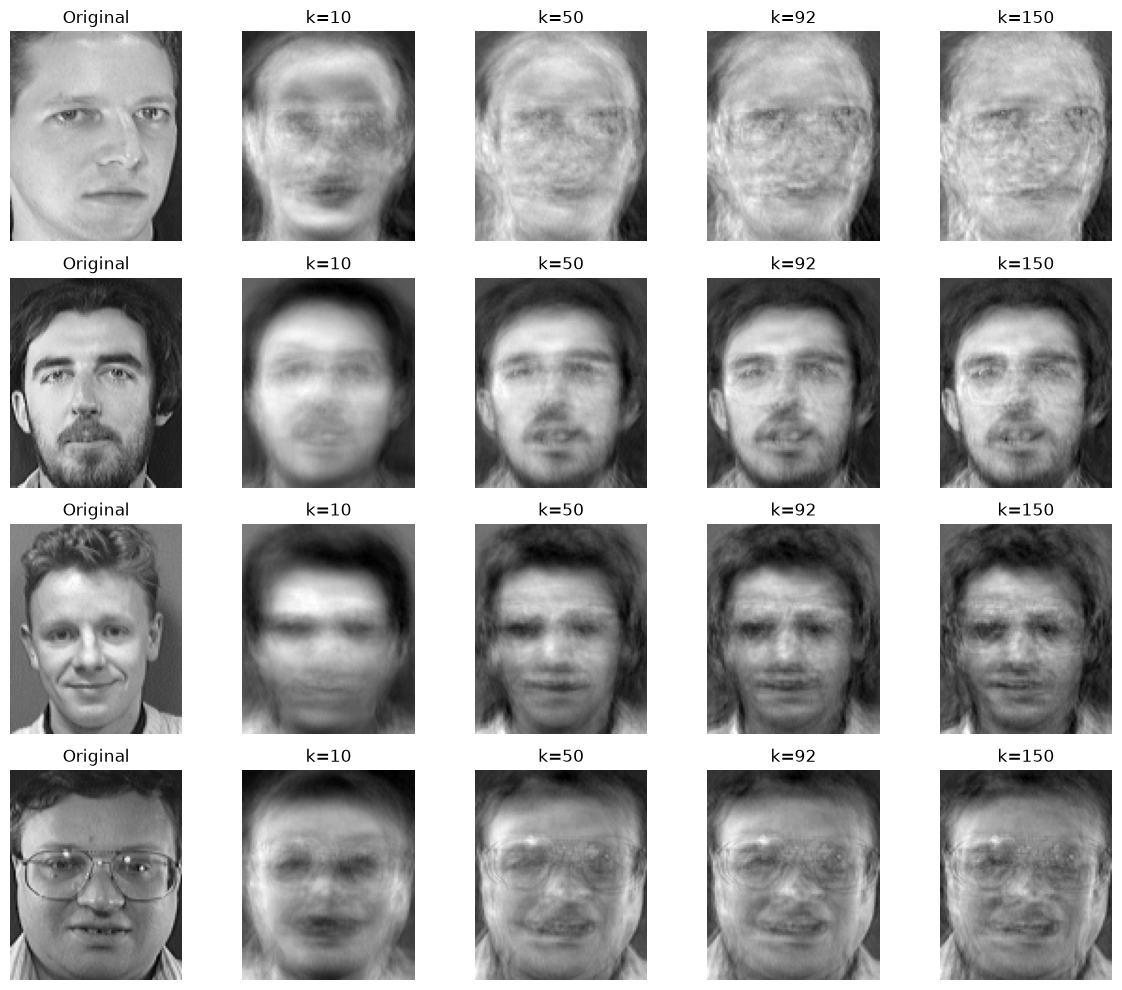


Original floats: 2885120
PCA floats     : 984032
Overall compression: 2.93x
Per-image: 10304 -> 92 numbers (112x smaller)


In [8]:
K = k90                               
W = components_svd[:K]               
Z_train = Xc_train @ W.T               
Z_test  = Xc_test  @ W.T                
print("Z_train:", Z_train.shape, "| Z_test:", Z_test.shape)

np.savez("pca_representation.npz", Z_train=Z_train, Z_test=Z_test,
         y_train=y_train, y_test=y_test, W=W, mean_face=mean_face)
def reconstruct(Z, k):
    return Z[:, :k] @ components_svd[:k] + mean_face

print("\nTest reconstruction MSE:")
for k in [10, 25, 50, K, 150]:
    Z_k = Xc_test @ components_svd[:k].T
    recon = Z_k @ components_svd[:k] + mean_face
    print(f"k={k:3d}  MSE={np.mean((X_test - recon) ** 2):8.2f}")
ks = [10, 50, K, 150]
sample = [0, 30, 60, 90]
fig, axes = plt.subplots(len(sample), len(ks) + 1, figsize=(12, 10))
for r, i in enumerate(sample):
    axes[r, 0].imshow(X_test[i].reshape(h, w), cmap="gray")
    axes[r, 0].set_title("Original")
    for c, k in enumerate(ks, start=1):
        rec = (Xc_test[i] @ components_svd[:k].T) @ components_svd[:k] + mean_face
        axes[r, c].imshow(rec.reshape(h, w), cmap="gray")
        axes[r, c].set_title(f"k={k}")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig("reconstructions.png", dpi=150)
plt.show()
n, d = X_train.shape
orig_floats = n * d
pca_floats = n * K + K * d + d 
print("\nOriginal floats:", orig_floats)
print("PCA floats     :", pca_floats)
print(f"Overall compression: {orig_floats / pca_floats:.2f}x")
print(f"Per-image: {d} -> {K} numbers ({d / K:.0f}x smaller)")

Part C

Raw pixels  (10304 features): accuracy = 0.9750
PCA         (92 features): accuracy = 0.9750
Errors raw: 3 | errors PCA: 3

PCA accuracy vs k:
k= 10  acc=0.9500
k= 25  acc=0.9667
k= 50  acc=0.9833
k= 92  acc=0.9750
k=100  acc=0.9750
k=150  acc=0.9833


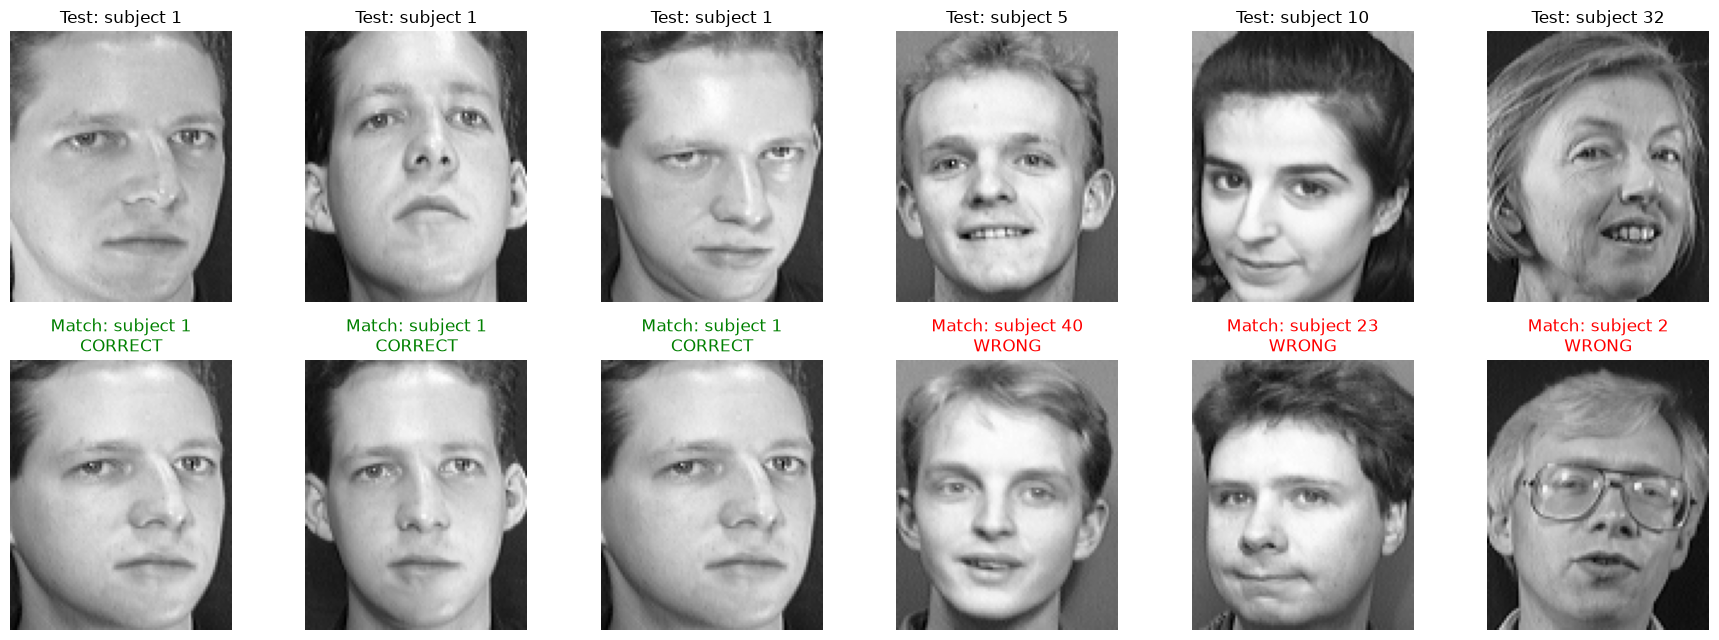

test idx 14: true=5, predicted=40, dist=1984.7
test idx 29: true=10, predicted=23, dist=3156.5
test idx 95: true=32, predicted=2, dist=3322.5


In [9]:
# --- Pairwise Euclidean distances: (n_test, n_train) ---
def pairwise_dist(A, B):
    # ||a-b||^2 = ||a||^2 + ||b||^2 - 2 a.b
    d2 = (A**2).sum(1)[:, None] + (B**2).sum(1)[None, :] - 2 * A @ B.T
    return np.sqrt(np.maximum(d2, 0))

def nn_predict(D, y_ref):
    nearest = D.argmin(axis=1)
    return y_ref[nearest], nearest

# --- Raw pixels ---
D_raw = pairwise_dist(X_test, X_train)
pred_raw, nn_raw = nn_predict(D_raw, y_train)
acc_raw = np.mean(pred_raw == y_test)

# --- PCA space (K = 92) ---
D_pca = pairwise_dist(Z_test, Z_train)
pred_pca, nn_pca = nn_predict(D_pca, y_train)
acc_pca = np.mean(pred_pca == y_test)

print(f"Raw pixels  ({X_train.shape[1]} features): accuracy = {acc_raw:.4f}")
print(f"PCA         ({K} features): accuracy = {acc_pca:.4f}")
print("Errors raw:", np.sum(pred_raw != y_test), "| errors PCA:", np.sum(pred_pca != y_test))

# --- Accuracy vs k (PCA space) ---
print("\nPCA accuracy vs k:")
for k in [10, 25, 50, K, 100, 150]:
    Zt = Xc_train @ components_svd[:k].T
    Zq = Xc_test  @ components_svd[:k].T
    p, _ = nn_predict(pairwise_dist(Zq, Zt), y_train)
    print(f"k={k:3d}  acc={np.mean(p == y_test):.4f}")

# --- Visualize correct and incorrect matches ---
correct = np.where(pred_pca == y_test)[0]
wrong   = np.where(pred_pca != y_test)[0]
show = list(correct[:3]) + list(wrong[:3])      # wrong may have fewer than 3

fig, axes = plt.subplots(2, len(show), figsize=(3 * len(show), 6.5))
for c, i in enumerate(show):
    ok = pred_pca[i] == y_test[i]
    axes[0, c].imshow(X_test[i].reshape(h, w), cmap="gray")
    axes[0, c].set_title(f"Test: subject {y_test[i]}")
    axes[1, c].imshow(X_train[nn_pca[i]].reshape(h, w), cmap="gray")
    axes[1, c].set_title(f"Match: subject {pred_pca[i]}\n{'CORRECT' if ok else 'WRONG'}",
                         color="green" if ok else "red")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig("recognition_matches.png", dpi=150)
plt.show()

# --- Which test images failed? ---
for i in wrong:
    print(f"test idx {i}: true={y_test[i]}, predicted={pred_pca[i]}, dist={D_pca[i].min():.1f}")

In [10]:
d_best = D_pca.min(axis=1)
print("Correct matches: median dist =", np.median(d_best[pred_pca == y_test]),
      "| 90th pct =", np.percentile(d_best[pred_pca == y_test], 90))
print("Wrong matches  :", d_best[pred_pca != y_test])

Correct matches: median dist = 1541.538049027886 | 90th pct = 2655.375740076305
Wrong matches  : [1984.66715381 3156.47105407 3322.45031839]


In [11]:
for i in np.where(pred_pca != y_test)[0]:
    d_true = D_pca[i, y_train == y_test[i]].min()
    d_pred = D_pca[i].min()
    print(f"test idx {i}: nearest true-subject photo = {d_true:.1f} | nearest wrong match = {d_pred:.1f}")

test idx 14: nearest true-subject photo = 2415.1 | nearest wrong match = 1984.7
test idx 29: nearest true-subject photo = 3225.6 | nearest wrong match = 3156.5
test idx 95: nearest true-subject photo = 3349.7 | nearest wrong match = 3322.5


In [12]:
Z_train_full = Xc_train @ components_svd[:150].T   # scores for up to 150 components

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "KNN (k=1)":   KNeighborsClassifier(n_neighbors=1),
    "LogReg":      make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Linear SVM":  make_pipeline(StandardScaler(), SVC(kernel="linear")),
}

k_values = [10, 25, 50, K, 100, 150]
results = {name: [] for name in models}

for k in k_values:
    Zk = Z_train_full[:, :k]
    for name, model in models.items():
        scores = cross_val_score(model, Zk, y_train, cv=cv)
        results[name].append(scores.mean())

print("CV accuracy (train only)")
print("k".ljust(6) + "".join(n.ljust(14) for n in models))
for i, k in enumerate(k_values):
    print(str(k).ljust(6) + "".join(f"{results[n][i]:<14.4f}" for n in models))

CV accuracy (train only)
k     KNN (k=1)     LogReg        Linear SVM    
10    0.8929        0.8679        0.9214        
25    0.9429        0.9393        0.9357        
50    0.9429        0.9464        0.9536        
92    0.9393        0.8893        0.8571        
100   0.9393        0.8714        0.8429        
150   0.9393        0.7679        0.6893        


In [15]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
Z_train_full = Xc_train @ components_svd[:150].T
Z_test_full  = Xc_test  @ components_svd[:150].T

scalers = [StandardScaler(), "passthrough"]

search_spaces = {
    "KNN": (
        Pipeline([("scale", "passthrough"), ("clf", KNeighborsClassifier())]),
        {"clf__n_neighbors": [1, 3, 5], "clf__weights": ["uniform", "distance"]},
    ),
    "LogReg": (
        Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=5000))]),
        {"scale": scalers, "clf__C": [0.01, 0.1, 1, 10, 100]},
    ),
    "Linear SVM": (
        Pipeline([("scale", StandardScaler()), ("clf", SVC(kernel="linear"))]),
        {"scale": scalers, "clf__C": [0.001, 0.01, 0.1, 1, 10]},
    ),
}

k_grid = [25, 35, 50, 65, 80]
best = {}   

for name, (pipe, grid) in search_spaces.items():
    for k in k_grid:
        gs = GridSearchCV(pipe, grid, cv=cv, n_jobs=-1)
        gs.fit(Z_train_full[:, :k], y_train)
        if name not in best or gs.best_score_ > best[name][0]:
            best[name] = (gs.best_score_, k, gs)
    s, k, gs = best[name]
    print(f"{name:11s} best CV={s:.4f} at k={k}  params={gs.best_params_}")

KNN         best CV=0.9464 at k=35  params={'clf__n_neighbors': 1, 'clf__weights': 'uniform'}
LogReg      best CV=0.9643 at k=50  params={'clf__C': 0.01, 'scale': 'passthrough'}
Linear SVM  best CV=0.9643 at k=35  params={'clf__C': 0.001, 'scale': 'passthrough'}


In [16]:
print("\nFINAL TEST RESULTS")
rows = [("Nearest neighbor (Part C, k=92)", 92, acc_pca)]
for name, (s, k, gs) in best.items():
    acc = gs.score(Z_test_full[:, :k], y_test)   
    rows.append((name, k, acc))

print(f"{'Model':34s}{'k':>5s}{'Test acc':>10s}")
for name, k, acc in rows:
    print(f"{name:34s}{k:>5d}{acc:>10.4f}")


FINAL TEST RESULTS
Model                                 k  Test acc
Nearest neighbor (Part C, k=92)      92    0.9750
KNN                                  35    0.9667
LogReg                               50    1.0000
Linear SVM                           35    0.9750


In [18]:
import pandas as pd
df = pd.DataFrame(rows, columns=["Model", "k", "Test accuracy"])
df["Test accuracy"] = df["Test accuracy"].round(4)
df.to_csv("ml_comparison.csv", index=False)
print(df.to_markdown(index=False))  


| Model                           |   k |   Test accuracy |
|:--------------------------------|----:|----------------:|
| Nearest neighbor (Part C, k=92) |  92 |          0.975  |
| KNN                             |  35 |          0.9667 |
| LogReg                          |  50 |          1      |
| Linear SVM                      |  35 |          0.975  |
